# 02 — El hospital: qué variables tenemos y qué mide cada una**Fecha:** 2026-09-22 · **Datos:** 433.620 triages, 2020-01-01 a 2026-09-21---## Qué contesta este cuadernoEl 01 miró **cuánta** gente viene y **cuándo**. Este mira **qué sabemos de cada consulta** y,sobre todo, **qué mide realmente cada variable** — que no siempre es lo que su nombre sugiere.Sin factores externos todavía. Primero hay que saber con qué cartas se juega.## La distinción que organiza todo el cuadernoNo todas las columnas miden lo mismo, y confundirlas es el error más caro que se puedecometer aquí:| | Qué mide | Variables ||---|---|---|| **La población** | Cuánta gente enferma y de qué | conteo, edad, hora de llegada || **La institución** | Qué decide el hospital con esa gente | nivel de triage, estancia |> **El conteo y la edad son un termómetro de Manizales. El nivel de triage y la estancia son> un termómetro del hospital.** Los dos sirven, pero contestan preguntas distintas, y una> variable del segundo grupo no se puede leer como si fuera del primero.Esta distinción no estaba clara al empezar y costó una interpretación equivocada, que secorrige en la sección 3.

In [1]:
import sys, pathlib
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from clustering.visualizaciones import datos, figuras

nivel = pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet")
edad  = pd.read_parquet(RAIZ / "salidas" / "triage_edad.parquet")
total = datos.marco(datos.total())

MES = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
print(f"nivel: {len(nivel):,} filas dia x hora x nivel")
print(f"edad : {len(edad):,} filas dia x banda")

nivel: 177,864 filas dia x hora x nivel
edad : 12,339 filas dia x banda


---# 1. El inventario: qué hay y desde cuándoMedido el 2026-09-22 con `python -m extraccion --cobertura`.| Variable | Qué es | Cobertura | Desde | ¿Sirve? ||---|---|---|---|---|| `HCTFECTRI` | Fecha y hora | **100 %** | 2020 | Sí, es el eje || `HCNCLAURGTR` | Nivel de triage | **100 %** | 2020 | Sí, **con reservas** (§3) || `HCTEDAD` | Edad | **100 %** | 2020 | Sí, en bandas (§4) || `HCCFECSAL` | Hora de salida → estancia | 91,1 % | 2020 | Solo régimen 2 || `HCTMOTCON` | Motivo, texto libre | 82,8 % / 76,2 % | **2025** | Pendiente del NLP || `GENDIAGNO1` | Diagnóstico CIE-10 | **0,6 %** | — | **No. Está vacío** |## Dos cosas que hay que saber antes de seguir**`GENDIAGNO1` casi fue el atajo del proyecto.** Apunta a `DIM_DIAGNOSTICO`, que tiene 12.427filas con códigos de 10 caracteres: es CIE-10. Si estuviera poblada, habría una clasificaciónclínica estructurada de cada triage desde 2020 y sobraría buena parte de la cadena de NLP.**No lo está**: 0,6 % global, y cero en 2022, 2025 y 2026. Queda escrito para no volver abuscarlo.**La única variable con el motivo clínico es texto libre y empieza en 2025.** Eso deja unaasimetría que manda sobre el plan entero:- Para **cuánta** gente viene y **de qué edad**: seis años y medio.- Para **de qué se queja**: veinte meses, y hay que procesarlos con un modelo local.

---# 2. Quién viene: la edadEs la variable menos mirada y la que más señal tiene. Está al 100 % desde 2020 y no dependede ningún modelo.

In [2]:
comp = edad.groupby("banda")["n"].sum()
comp = 100 * comp / comp.sum()
orden = ["0-4", "5-14", "15-44", "45-64", "65-+"]
print("COMPOSICION POR EDAD (6,7 anios)")
for b in orden:
    print(f"  {b:<8}{comp[b]:5.1f}%  " + "#" * int(comp[b]))

edad["anio"] = edad["dia"].dt.year
por_anio = edad.pivot_table(index="anio", columns="banda", values="n", aggfunc="sum").fillna(0)
cuota = 100 * por_anio.div(por_anio.sum(axis=1), axis=0)
print("\nCUOTA POR ANIO (%)")
print(cuota[orden].round(1).to_string())

COMPOSICION POR EDAD (6,7 anios)
  0-4       3.1%  ###
  5-14      4.4%  ####
  15-44    54.4%  ######################################################
  45-64    18.5%  ##################
  65-+     19.5%  ###################

CUOTA POR ANIO (%)
banda  0-4  5-14  15-44  45-64  65-+
anio                                
2020   1.9   3.0   55.1   19.8  20.2
2021   2.4   3.0   57.9   18.7  17.9
2022   3.2   4.5   56.5   17.9  17.8
2023   2.7   4.2   55.7   18.4  18.9
2024   3.0   4.5   53.8   18.9  19.5
2025   3.9   5.6   51.0   18.3  20.9
2026   4.0   5.1   51.0   18.0  21.8


## Lectura**El 54,4 % de las consultas son de personas entre 15 y 44 años.** Población en edadlaboral. Los menores de 15 son apenas el 7,5 %.Eso es información directa sobre el mecanismo que el proyecto quiere medir. Un serviciodonde una de cada dos consultas es de alguien en edad de trabajar encaja con la hipótesis departida — la persona que necesita el soporte del día — mucho mejor que un serviciopediátrico o geriátrico.**Y la composición se está moviendo, de forma consistente:**| Banda | 2021 | 2026 | ||---|---|---|---|| 0-4 | 2,4 % | **4,0 %** | ↑ || 5-14 | 3,0 % | **5,1 %** | ↑ || 15-44 | 57,9 % | **51,0 %** | ↓ || 65+ | 17,9 % | **21,8 %** | ↑ |**Los extremos de edad ganan peso y el centro lo pierde.** Es coherente con lo que seencontró en el cuaderno 01: si la población adulta de baja complejidad se está desviando aotro sitio, lo que queda pesa más hacia niños y mayores. Las dos observaciones se explicancon el mismo cambio.

## 2.1 La estacionalidad por edad — el hallazgo del cuaderno

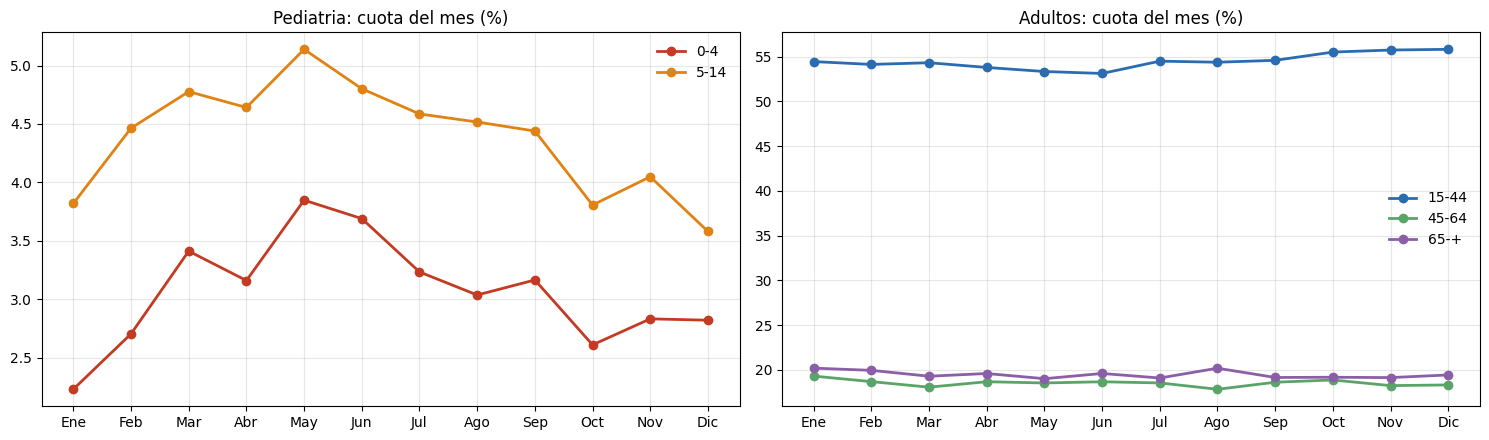

AMPLITUD ESTACIONAL DE CADA BANDA (max/min - 1)
  0-4      max May ( 3.85%)   min Ene ( 2.23%)   amplitud  72.5%
  5-14     max May ( 5.14%)   min Dic ( 3.58%)   amplitud  43.5%
  15-44    max Dic (55.82%)   min Jun (53.12%)   amplitud   5.1%
  45-64    max Ene (19.29%)   min Ago (17.82%)   amplitud   8.3%
  65-+     max Ene (20.18%)   min May (19.00%)   amplitud   6.2%


In [3]:
edad["mes"] = edad["dia"].dt.month
pm = edad.pivot_table(index="mes", columns="banda", values="n", aggfunc="sum").fillna(0)
cm = 100 * pm.div(pm.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for b, c in zip(["0-4", "5-14"], ["#c23b22", "#e08214"]):
    ax1.plot(range(1, 13), cm[b], marker="o", lw=2, label=b, color=c)
ax1.set_title("Pediatria: cuota del mes (%)", fontsize=12)
for b, c in zip(["15-44", "45-64", "65-+"], ["#2b6cb0", "#5aa469", "#8b5fa8"]):
    ax2.plot(range(1, 13), cm[b], marker="o", lw=2, label=b, color=c)
ax2.set_title("Adultos: cuota del mes (%)", fontsize=12)
for ax in (ax1, ax2):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.legend(frameon=False)
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("AMPLITUD ESTACIONAL DE CADA BANDA (max/min - 1)")
for b in orden:
    s = cm[b]
    print(f"  {b:<8} max {MES[s.idxmax()-1]} ({s.max():5.2f}%)   min {MES[s.idxmin()-1]} ({s.min():5.2f}%)"
          f"   amplitud {100*(s.max()/s.min()-1):5.1f}%")

## Lectura — esto es lo más importante que ha salido hasta ahora| Banda | Amplitud estacional | Pico | Valle ||---|---|---|---|| **0-4** | **72,5 %** | **Mayo** | Enero || **5-14** | **43,5 %** | **Mayo** | Diciembre || 45-64 | 8,3 % | Enero | Agosto || 65+ | 6,2 % | Enero | Mayo || 15-44 | 5,1 % | Diciembre | Junio |> **Las bandas pediátricas tienen entre 7 y 14 veces más amplitud estacional que las> adultas.** Y no oscilan en cualquier dirección: suben juntas de marzo a junio y caen juntas> de octubre a enero.**Esa es la firma clásica de una temporada respiratoria.** Los niños son el indicadoradelantado de la circulación viral, y en Colombia el primer pico de infección respiratoriaaguda está documentado entre marzo y mayo.### Y encaja con la lluvia, pero solo a mediasLa precipitación corregida de Manizales (ver nota de la sección 5) es **bimodal**: picos en**abril** y en **octubre-noviembre**, valles en enero y julio.- **El primer pico de lluvia (abril) precede en un mes al pico pediátrico (mayo).** Un rezago  de esa magnitud es exactamente lo que predice el mecanismo: incubación más decisión de  consultar.- **El segundo pico de lluvia (octubre-noviembre) NO tiene pico pediátrico detrás.** Ahí la  cuota de 0-4 está en su mínimo.### Qué significa que solo encaje a medias**Que la lluvia sola no lo explica, y está bien que así sea.** Si encajaran los dos picos, laexplicación más simple sería estacionalidad compartida y no un mecanismo. Que encaje uno y noel otro obliga a buscar qué distingue abril de octubre — y ahí entran el calendario escolar,la circulación viral de cada año y la temperatura.**Es una hipótesis falsable y con los datos para probarla ya en el repositorio.** No requiereuna sola nota de texto.### Límites- Esto es el **promedio de siete años**. Un promedio puede esconder que cada año el pico cae  en un mes distinto. Hay que mirarlo año a año antes de darlo por bueno.- **La cuota no es el conteo.** Que suba la cuota de 0-4 puede ser porque vienen más niños o  porque vienen menos adultos. Hay que verlo también en absoluto.- El calendario escolar colombiano y la temporada de lluvias se solapan. **Están confundidos**  y separarlos requiere un diseño, no una figura.

---# 3. El nivel de triage — y una corrección de interpretaciónEl nivel está al 100 % desde 2020. Pero **mide algo distinto de lo que parece**, y en lasesión anterior se interpretó mal.

In [4]:
resumen = (nivel.groupby(["nivel", "nivel_nombre"])["n"].sum()
           .sort_values(ascending=False).reset_index())
resumen["cuota"] = 100 * resumen["n"] / resumen["n"].sum()
print(f"{'nivel':<8}{'descripcion':<44}{'n':>10}{'cuota':>8}")
for _, r in resumen.head(8).iterrows():
    print(f"{r.nivel:<8}{str(r.nivel_nombre)[:42]:<44}{r.n:>10,}{r.cuota:>7.1f}%")

nivel   descripcion                                          n   cuota
IV      DIFERIDA/NO URGENTE                            169,764   39.2%
IIIU    URGENCIA                                       106,626   24.6%
V       CONSULTA EXTERNA                                53,014   12.2%
III-G   URGENCIA OBSTETRICA DIFERIDA O MENOR            47,330   10.9%
III     DIFERIDA                                        41,781    9.6%
II      URGENCIA MEDICA                                  6,479    1.5%
II-G    URGENCIA MEDICA OBSTETRICA                       6,302    1.5%
I       EMERGENCIA                                       1,463    0.3%


## La correcciónAl ver que el 51,4 % de los triages son «no urgente» o «consulta externa», la lecturainmediata fue que el hospital recibe consultas que no lo ameritan. **Esa lectura esincorrecta**, y la corrigió el propietario con un argumento que los datos no pueden dar:> *«el hospital no está en la capacidad de recibir a cualquier persona e ingresarlo y> tratarlo, directamente es inviable […] yo he venido con dolores muy fuertes pensando que me> voy a morir y lo que me dicen es que no es tan grave y que me vaya para la EPS con cita> prioritaria. Lo más seguro es que me marcan como no urgente o diferido y pasan al> siguiente.»***El nivel de triage no califica la legitimidad de la consulta. Califica qué va a hacer elhospital con ella.** Son dos cosas distintas:| | ||---|---|| Lo que el nivel **no** dice | Si el paciente tenía razón en venir || Lo que el nivel **sí** dice | Si este servicio lo va a atender aquí o lo remite |Un «no urgente» es una persona que llegó con un síntoma real y a la que se le resolvió porotra vía. **Como dato de demanda poblacional es tan válido como un «urgente».**### Las tres consecuencias1. **Todos los registros se tratan como verídicos.** No hay forma de separar quién exageró, y   tampoco hace falta: el conteo mide que alguien sintió la necesidad de consultar, que es   justamente lo que el proyecto quiere predecir.2. **El nivel es una variable de la institución, no de la población.** Depende del criterio   del personal y de la capacidad del servicio en ese momento. Sirve para caracterizar al   hospital y para entender qué prioriza — no para medir la gravedad de lo que pasa en la   ciudad.3. **El umbral puede moverse con la presión del servicio.** Y eso lo vuelve interesante por   otro motivo: **un nivel que se endurece puede ser en sí mismo un indicador de saturación.**

## 3.1 La deriva del criterio

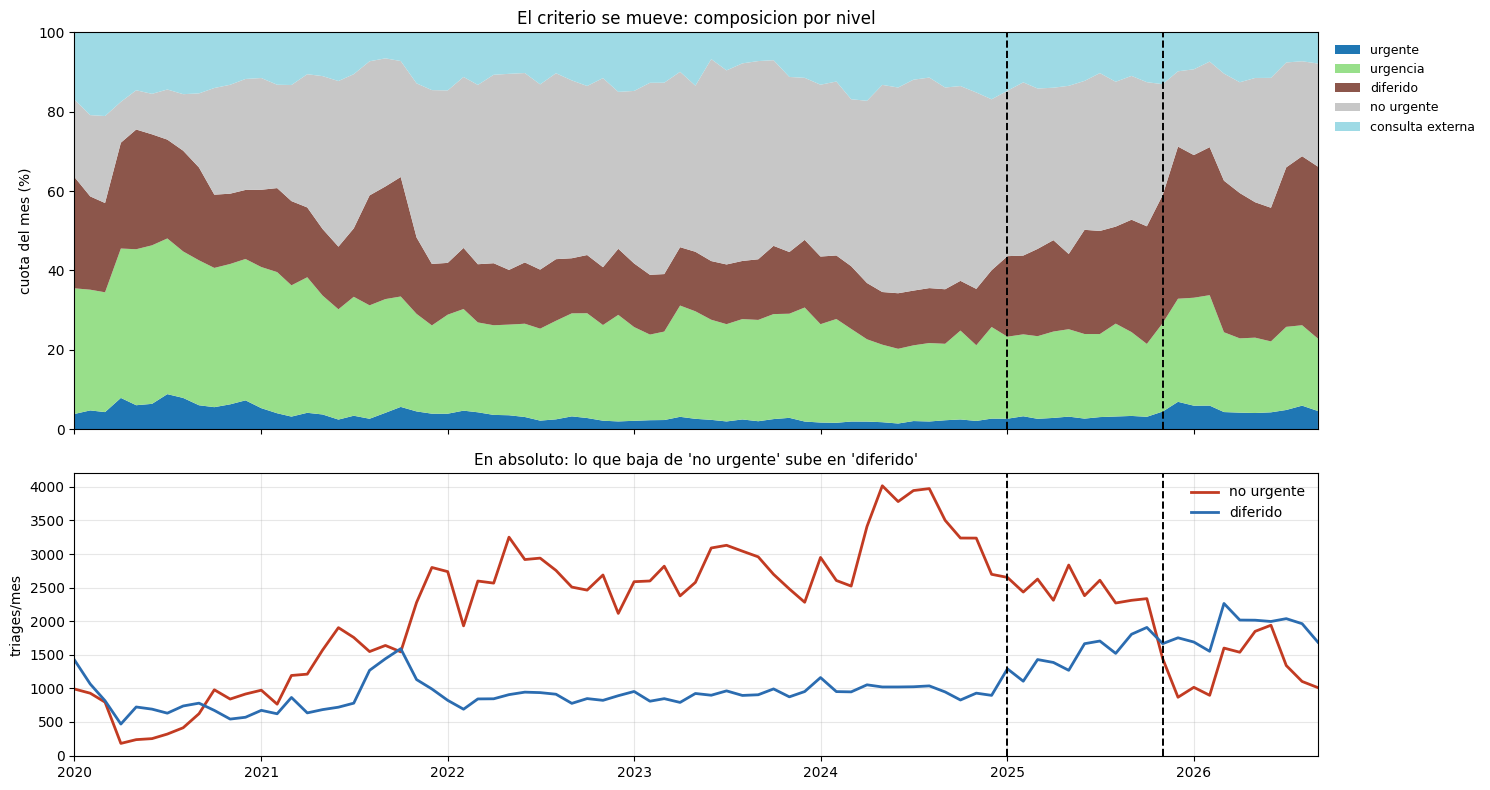

In [5]:
GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
orden_g = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]

mens = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)[orden_g]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                               gridspec_kw={"height_ratios": [1.4, 1]})
x = mens.index.to_timestamp()
cuota_m = 100 * mens.div(mens.sum(axis=1), axis=0)
ax1.stackplot(x, cuota_m.to_numpy().T, labels=cuota_m.columns,
              colors=plt.get_cmap("tab20")(np.linspace(0, 1, mens.shape[1])))
ax1.set_ylim(0, 100); ax1.set_ylabel("cuota del mes (%)")
ax1.set_title("El criterio se mueve: composicion por nivel", fontsize=12)
ax1.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9, frameon=False)

for c, col in zip(["no urgente", "diferido"], ["#c23b22", "#2b6cb0"]):
    ax2.plot(x, mens[c], lw=2, label=c, color=col)
ax2.set_ylabel("triages/mes"); ax2.legend(frameon=False); ax2.grid(alpha=.3)
ax2.set_title("En absoluto: lo que baja de 'no urgente' sube en 'diferido'", fontsize=11)
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.4, ls="--")
    ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.4, ls="--")
ax1.set_xlim(x.min(), x.max())
plt.tight_layout(); plt.show()

## Lectura**El panel de abajo es la prueba.** «No urgente» cae y «diferido» sube, en absoluto y casi enespejo. No es que dejen de venir: es que **los mismos pacientes reciben otra etiqueta**.La deriva arranca en **enero de 2025** y se acelera en **noviembre-diciembre de 2025**.Hay dos explicaciones posibles y no son excluyentes:1. **Cambió el criterio** — la misma persona que en 2024 era IV, en 2026 es III.2. **Cambió quién llega** — los de menor complejidad se desviaron a otro sitio.**La segunda sola no basta**: si solo fuera desvío, «diferido» no subiría en términosabsolutos, y sube casi el doble. Hay reetiquetado.> **Consecuencia operativa: un «triage IV» de 2024 y uno de 2026 no son la misma cosa.** El> nivel sirve dentro de un periodo, no entre periodos. Para comparar años hay que usar el> conteo total y la edad, que no dependen del criterio de nadie.

---# 4. Qué queda en pie — el mapa de variables

In [6]:
filas = [
    ("conteo total",      "poblacion",   "100%", "2020", "si",  "el desenlace"),
    ("edad en bandas",    "poblacion",   "100%", "2020", "si",  "senal estacional fuerte"),
    ("hora de llegada",   "poblacion",   "100%", "2020", "si",  "13,9x de oscilacion"),
    ("nivel de triage",   "institucion", "100%", "2020", "con reservas", "deriva desde 2025"),
    ("estancia",          "institucion", "91%",  "2020", "con reservas", "solo regimen 2"),
    ("motivo (texto)",    "poblacion",   "80%",  "2025", "pendiente", "1,5% procesado"),
    ("diagnostico CIE-10","poblacion",   "0,6%", "-",    "no",  "esta vacio"),
]
print(f"{'variable':<20}{'mide':<13}{'cobert':<8}{'desde':<7}{'usable':<15}{'nota'}")
for f in filas:
    print(f"{f[0]:<20}{f[1]:<13}{f[2]:<8}{f[3]:<7}{f[4]:<15}{f[5]}")

variable            mide         cobert  desde  usable         nota
conteo total        poblacion    100%    2020   si             el desenlace
edad en bandas      poblacion    100%    2020   si             senal estacional fuerte
hora de llegada     poblacion    100%    2020   si             13,9x de oscilacion
nivel de triage     institucion  100%    2020   con reservas   deriva desde 2025
estancia            institucion  91%     2020   con reservas   solo regimen 2
motivo (texto)      poblacion    80%     2025   pendiente      1,5% procesado
diagnostico CIE-10  poblacion    0,6%    -      no             esta vacio


## Lo que esto deja para la fase de predicción**Tres variables limpias, al 100 % y con 6,7 años**: el conteo, la edad y la hora. Con esosolo ya se puede:- Construir el control de calendario en serio (cuaderno 03).- Probar la hipótesis respiratoria por la vía pediátrica, **sin una sola nota de texto**.- Medir contra seis años y medio en vez de veinte meses.**Dos variables con reserva**: el nivel y la estancia. Usables dentro de su régimen, no entreregímenes. Y las dos son de la institución: dicen cómo responde el hospital, no cuánta genteenferma.**Una pendiente**: el motivo. Es el desenlace específico y sigue siendo el que más valorañade — pero llega en 2025, justo cuando empieza la deriva, y va por el 1,5 %.

---# 5. Nota: el clima de Manizales, y un error en los datos que ya existenEste cuaderno no usa clima. Pero al verificar el contexto geográfico apareció algo que hayque dejar dicho antes de que alguien construya encima.## Lo que dicen los datos sobre el clima de aquíMedido sobre `calendarios/clima_unificado.csv`, 2.432 días:| | ||---|---|| Temperatura media | 16,5 °C (sd 0,64) || Temperatura máxima media | 21,2 °C || **Días con máxima > 26 °C, en 6,7 años** | **0** || Días con máxima > 25 °C | 5 (0,21 %) || Humedad media | 87,2 % |**Aquí no hace calor. Nunca.** En 2.432 días la máxima no llegó a 26 °C ni una sola vez.Manizales está a ~2.150 m en la Cordillera Central, junto al Nevado del Ruiz, y eso se ve enlos datos: el rango térmico anual completo cabe en cuatro grados.**Consecuencia para las hipótesis:** el mecanismo vectorial (dengue, chikunguña) necesitacalor sostenido y aquí no lo hay. La vía local queda descartada; lo que queda son pacientesremitidos de municipios bajos de Caldas, y las epidemias que sí encajan con este clima:respiratorias, virales, fúngicas. Que es la hipótesis original del proyecto.## El error: `precip_consenso_mm` está inflado y con el ciclo invertido| Fuente | mm/año | Pico | Valle ||---|---|---|---|| Estación IDEAM | 1.403 | Abr | Feb || NASA POWER | 1.904 | Abr | Jul || **Open-Meteo** | **16.555** | **Jul** | **Ene** || **Consenso actual** | **4.393** | **Jun** | Ene |Manizales recibe unos **2.000 mm/año**. Open-Meteo reporta **16.555** — ocho veces más que larealidad y más que el lugar más lluvioso del planeta. Y su ciclo anual está invertidorespecto a la climatología conocida.**Por qué se cuela en el consenso:** `clima_unificado.py` toma la **mediana** de las tresfuentes. Con tres, Open-Meteo queda fuera de la mediana y no hace daño. Pero **la estaciónIDEAM solo cubre el 72,6 % de los días**, y en el 27,6 % restante la mediana de dos valoreses su promedio:| Días con | Consenso resultante ||---|---|| 3 fuentes (72,2 %) | 6,55 mm/día ✔ || **2 fuentes (27,6 %)** | **26,40 mm/día** ✘ |**La causa raíz está escrita en el propio script**, `clima_manizales.py` línea 68: *«era5_landNO devuelve precipitation_sum → la precipitación se pide aparte al modelo era5»*. Ese modelotiene celdas de ~28 km; en la Cordillera Central una celda así promedia el valle delMagdalena con la montaña.## El arreglo, y lo que aparece al hacerloQuitando Open-Meteo de la mediana: **1.765 mm/año** — dentro del rango real — y el cicloanual se vuelve **bimodal**, como debe ser:- Picos en **abril** (6,99 mm/día) y **octubre-noviembre** (5,43 / 5,70)- Valles en **enero** (3,36) y **julio** (3,52)**Y con esa serie corregida es con la que hay que releer la sección 2.1**: el pico pediátricode mayo va justo detrás del pico de lluvia de abril.> **Todo lo que dependa de `precip_consenso_mm`, `precip_7d`, `precip_30d`, `llovio` o> `lluvia_fuerte` está calculado sobre una variable rota.** Eso incluye las cifras de> `patrones/` y la afirmación de que «llovió» es cierta el 98,8 % de los días — que es cierta> del dato inflado, no del clima de Manizales.

---# Conclusiones## Lo que ahora se sabe del hospital1. **El 54,4 % de las consultas son de personas de 15 a 44 años.** Población laboral, que es   la que encaja con el mecanismo del soporte de incapacidad.2. **Los extremos de edad ganan peso**: 0-4 de 2,4 % a 4,0 %, 65+ de 17,9 % a 21,8 %.3. **Las bandas pediátricas tienen 7-14× más estacionalidad que las adultas**, con pico en   mayo y valle en enero. Es la firma de una temporada respiratoria.4. **El nivel de triage mide la decisión del hospital, no la gravedad del paciente.** Todos   los registros son demanda real.5. **El criterio del nivel derivó desde enero de 2025**, con reetiquetado demostrable.6. **No hay diagnóstico CIE-10**: la columna existe y está vacía.## Lo que este cuaderno cambia en el plan- **La vía pediátrica se adelanta.** Prueba la hipótesis respiratoria con 6,7 años y sin  depender del NLP. Pasa a ser el camino principal, no el alternativo.- **Hay que arreglar la precipitación antes de tocar cualquier cruce con clima.**- **Las comparaciones entre años se hacen con conteo y edad**, nunca con nivel.## Lo que queda abierto- **¿La estacionalidad pediátrica se repite cada año, o el promedio la fabrica?** Hay que  verla año a año. Es lo primero del próximo cuaderno.- **¿Es la lluvia, el calendario escolar o la circulación viral?** Los tres se solapan en  marzo-junio. Separarlos requiere diseño, no una figura más.- **¿Qué pasó en enero y noviembre de 2025?** Sigue sin respuesta y sigue condicionando qué  ventana de años es modelable.